# 04 · Gradient Boosting

In [1]:
# Librerías base
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Funciones compartidas del proyecto (métricas, gráficas, rutas) -> archivo churn_utils.py
from churn_utils import *

pd.options.display.max_columns = None
plt.rcParams["figure.dpi"] = 100

from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, classification_report, log_loss
import time

In [2]:
# Cargar los datos ya preparados por el notebook 00 (mismo train/test para TODOS los modelos)
datos = cargar_datos_modelo()
X_train, X_test = datos["X_train"], datos["X_test"]
y_train, y_test = datos["y_train"], datos["y_test"]

print("Entrenamiento:", X_train.shape, "| Test:", X_test.shape)
print("Tasa de fuga en train: %.2f%% | en test: %.2f%%" % (100 * y_train.mean(), 100 * y_test.mean()))

Entrenamiento: (8101, 33) | Test: (2026, 33)
Tasa de fuga en train: 16.07% | en test: 16.04%


## 1. Gradient Boosting a mano
Mismo principio del método del gradiente (notebook 01): cada árbol se entrena sobre el residuo `y - p`.

Tiempo: 3.9 s
AUC en test del Gradient Boosting hecho a mano: 0.9797


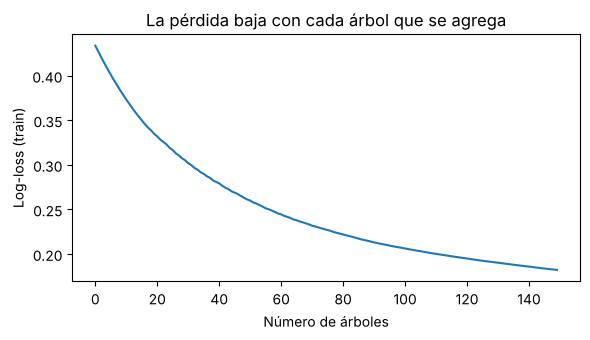

In [3]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

def gradient_boosting_manual(X, y, X_eval, n_arboles=100, learning_rate=0.1, max_depth=3):
    y = np.asarray(y)
    # Paso 0: predicción inicial = log-odds de la tasa de fuga (una constante)
    F0 = np.log(y.mean() / (1 - y.mean()))
    F_train = np.full(len(y), F0)
    F_eval = np.full(len(X_eval), F0)
    historia = []
    for m in range(n_arboles):
        p = sigmoide(F_train)                     # probabilidad actual
        residuo = y - p                           # gradiente negativo de la log-loss
        arbol = DecisionTreeRegressor(max_depth=max_depth, random_state=SEMILLA).fit(X, residuo)
        F_train += learning_rate * arbol.predict(X)    # paso en la dirección del gradiente
        F_eval += learning_rate * arbol.predict(X_eval)
        historia.append(log_loss(y, sigmoide(F_train)))
    return sigmoide(F_eval), historia

inicio = time.time()
prob_manual, historia = gradient_boosting_manual(X_train.values, y_train, X_test.values, n_arboles=150)
print("Tiempo: %.1f s" % (time.time() - inicio))
print("AUC en test del Gradient Boosting hecho a mano: %.4f" % roc_auc_score(y_test, prob_manual))

plt.figure(figsize=(6, 3.5)); plt.plot(historia)
plt.xlabel("Número de árboles"); plt.ylabel("Log-loss (train)"); plt.title("La pérdida baja con cada árbol que se agrega")
plt.tight_layout(); plt.show()

* Con 150 árboles hechos a mano el AUC ya es muy alto.

## 2. GBM por defecto

Métricas del modelo: GBM (por defecto)  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1681   48]
 [  20  277]]
 Accuracy        : 0.9664
 Sensibilidad    : 0.8523
 Especificidad   : 0.9882
 Precision (VPP) : 0.9327
 VPN             : 0.9722
 F1              : 0.8907
 AUC             : 0.9916
 PR-AUC          : 0.9621


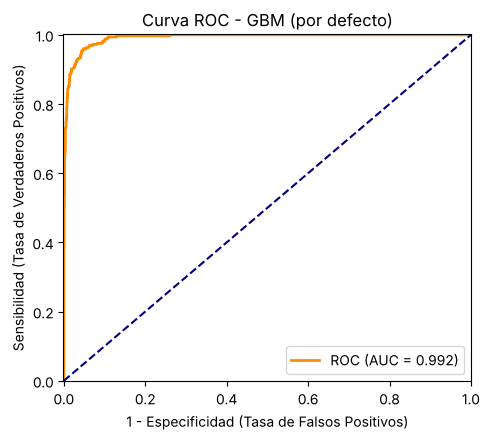

In [4]:
classifier_GBM = GradientBoostingClassifier(random_state=SEMILLA)
classifier_GBM.fit(X_train, y_train)

y_pred_prob = classifier_GBM.predict_proba(X_test)[:, 1]
metricas_gbm_default = evaluar_modelo("GBM (por defecto)", y_test, y_pred_prob)

## 3. Número de árboles vs. pérdida de validación

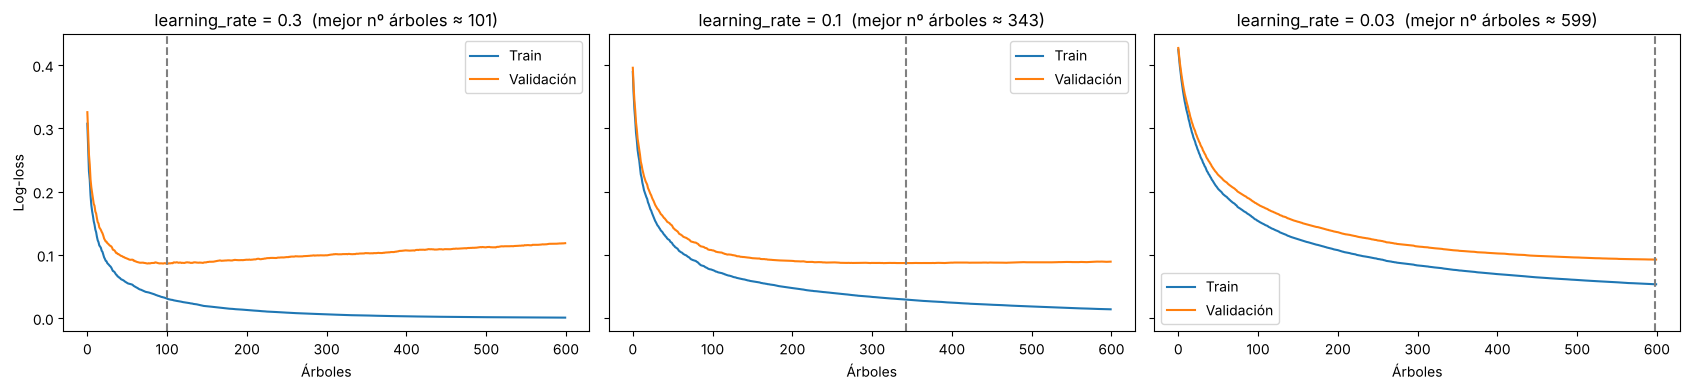

In [5]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEMILLA)

curvas = {}
for lr in [0.3, 0.1, 0.03]:
    m = GradientBoostingClassifier(n_estimators=600, learning_rate=lr, max_depth=3, random_state=SEMILLA).fit(X_tr, y_tr)
    curvas[lr] = {"train": [log_loss(y_tr, p[:, 1]) for p in m.staged_predict_proba(X_tr)],
                  "val": [log_loss(y_val, p[:, 1]) for p in m.staged_predict_proba(X_val)]}

fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, (lr, c) in zip(axes, curvas.items()):
    ax.plot(c["train"], label="Train"); ax.plot(c["val"], label="Validación")
    mejor = int(np.argmin(c["val"])); ax.axvline(mejor, color="gray", ls="--")
    ax.set_title(f"learning_rate = {lr}  (mejor nº árboles ≈ {mejor + 1})"); ax.set_xlabel("Árboles"); ax.legend()
axes[0].set_ylabel("Log-loss")
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/gbm_curvas_aprendizaje.png", bbox_inches="tight"); plt.show()

* La validación llega a un mínimo y luego se estanca o sube → sobreajuste.

## 4. GridSearchCV

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

param_grid = {"n_estimators": [200, 400],
              "learning_rate": [0.05, 0.1],
              "max_depth": [3, 5],
              "subsample": [0.8, 1.0]}

grid_search = GridSearchCV(estimator=GradientBoostingClassifier(random_state=SEMILLA), param_grid=param_grid,
                           cv=cv, scoring="roc_auc", return_train_score=True, n_jobs=-1, verbose=1)
inicio = time.time()
grid_search_GBM = grid_search.fit(X_train, y_train)
print("Tiempo: %.1f s" % (time.time() - inicio))
print("Mejores hiperparámetros:", grid_search_GBM.best_params_)
print("Mejor AUC validación cruzada: %.4f" % grid_search_GBM.best_score_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


Tiempo: 281.3 s
Mejores hiperparámetros: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400, 'subsample': 1.0}
Mejor AUC validación cruzada: 0.9926


In [7]:
res = pd.DataFrame(grid_search_GBM.cv_results_)
res["brecha_train_val"] = res["mean_train_score"] - res["mean_test_score"]
res[["params", "mean_train_score", "mean_test_score", "brecha_train_val", "rank_test_score"]].sort_values("rank_test_score").head(8).round(4)

,params,mean_train_score,mean_test_score,brecha_train_val,rank_test_score
11,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.9999,0.9926,0.0073,1
14,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",1.0000,0.9923,0.0077,2
10,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",1.0000,0.9923,0.0077,3
6,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",1.0000,0.9922,0.0078,4
12,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",1.0000,0.9922,0.0078,5
2,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.9989,0.9918,0.0071,6
3,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.9988,0.9917,0.0071,7
8,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.9989,0.9917,0.0073,8


Métricas del modelo: Gradient Boosting (ajustado)  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1675   29]
 [  26  296]]
 Accuracy        : 0.9729
 Sensibilidad    : 0.9108
 Especificidad   : 0.9847
 Precision (VPP) : 0.9193
 VPN             : 0.9830
 F1              : 0.9150
 AUC             : 0.9945
 PR-AUC          : 0.9747


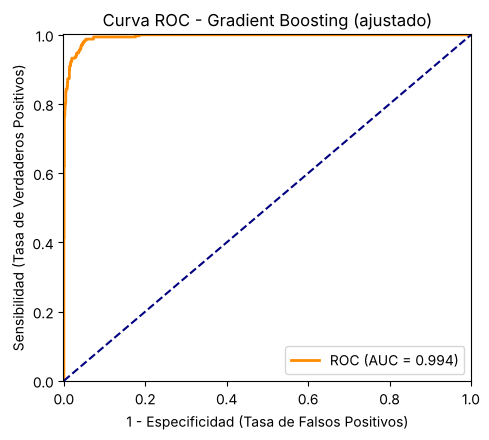

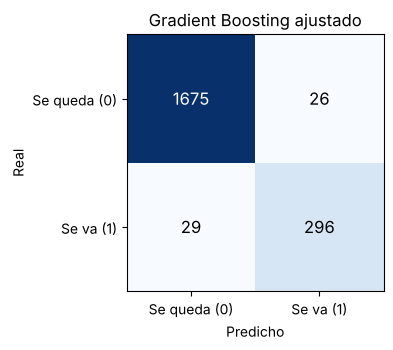

              precision    recall  f1-score   support

    Se queda       0.98      0.98      0.98      1701
       Se va       0.92      0.91      0.91       325

    accuracy                           0.97      2026
   macro avg       0.95      0.95      0.95      2026
weighted avg       0.97      0.97      0.97      2026

Resultados guardados en: resultados/Gradient_Boosting.pkl


In [8]:
# Evaluar el mejor GBM en TEST
y_pred_prob_gbm = grid_search_GBM.predict_proba(X_test)[:, 1]
metricas_gbm = evaluar_modelo("Gradient Boosting (ajustado)", y_test, y_pred_prob_gbm)
plot_confusion(y_test, np.where(y_pred_prob_gbm > 0.5, 1, 0), "Gradient Boosting ajustado")
print(classification_report(y_test, np.where(y_pred_prob_gbm > 0.5, 1, 0), target_names=["Se queda", "Se va"]))
guardar_resultados("Gradient Boosting", y_test, y_pred_prob_gbm, metricas_gbm, grid_search_GBM.best_params_)

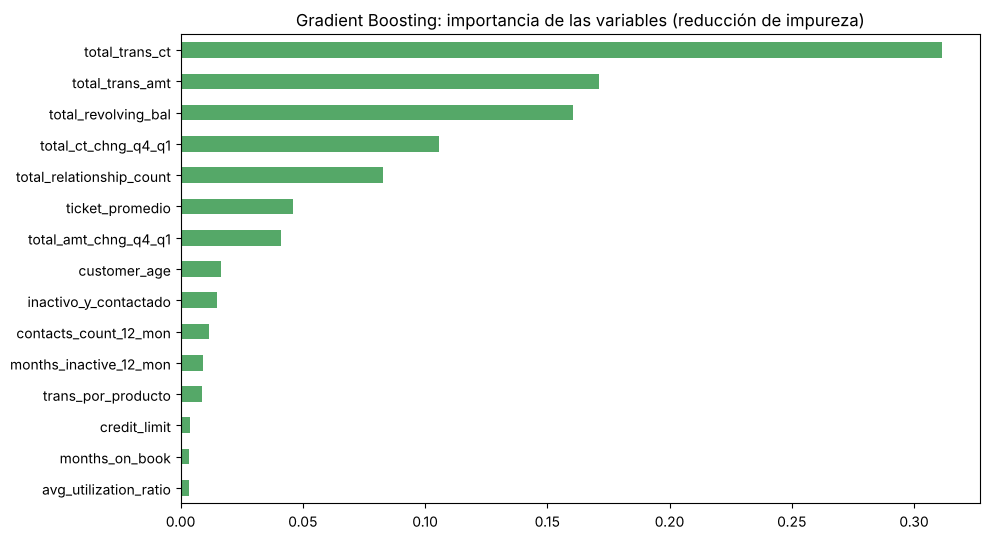

total_trans_ct              0.3114
total_trans_amt             0.1713
total_revolving_bal         0.1606
total_ct_chng_q4_q1         0.1058
total_relationship_count    0.0826
ticket_promedio             0.0460
total_amt_chng_q4_q1        0.0411
customer_age                0.0165
inactivo_y_contactado       0.0149
contacts_count_12_mon       0.0117
dtype: float64

In [9]:
# ¿Cuáles son las variables más importantes?
importances = grid_search_GBM.best_estimator_.feature_importances_
feature_importances = pd.Series(importances, index=X_train.columns)

plt.figure(figsize=(10, 5.5))
feature_importances.nlargest(15).sort_values().plot(kind="barh", color="#55A868")
plt.title("Gradient Boosting: importancia de las variables (reducción de impureza)")
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/gbm_importancia.png", bbox_inches="tight"); plt.show()
feature_importances.nlargest(10).round(4)

* Variables más importantes: transacciones, valor transado, saldo rotativo, cambio Q4→Q1 y productos.

## 5. HistGradientBoosting (con early stopping)

In [10]:
grid_hgb = GridSearchCV(
    HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, validation_fraction=0.15,
                                   n_iter_no_change=30, random_state=SEMILLA),
    param_grid={"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31], "l2_regularization": [0, 1.0],
                "class_weight": [None, "balanced"]},
    cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
print("Mejores hiperparámetros:", grid_hgb.best_params_, "| AUC CV: %.4f" % grid_hgb.best_score_)
print("Árboles usados (early stopping):", grid_hgb.best_estimator_.n_iter_)

y_pred_prob_hgb = grid_hgb.predict_proba(X_test)[:, 1]
metricas_hgb = evaluar_modelo("HistGradientBoosting", y_test, y_pred_prob_hgb, graficar=False)
guardar_resultados("HistGradientBoosting", y_test, y_pred_prob_hgb, metricas_hgb, grid_hgb.best_params_)

Mejores hiperparámetros: {'class_weight': 'balanced', 'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_leaf_nodes': 15} | AUC CV: 0.9928
Árboles usados (early stopping): 186
Métricas del modelo: HistGradientBoosting  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1658   17]
 [  43  308]]
 Accuracy        : 0.9704
 Sensibilidad    : 0.9477
 Especificidad   : 0.9747
 Precision (VPP) : 0.8775
 VPN             : 0.9899
 F1              : 0.9112
 AUC             : 0.9947
 PR-AUC          : 0.9744
Resultados guardados en: resultados/HistGradientBoosting.pkl


## Resumen Gradient Boosting
* Mejor GBM: 400 árboles, learning rate 0,1, profundidad 3 → AUC test 0,9945.
* HistGradientBoosting: AUC 0,9947.
* Entrega importancia de variables → más explicable que SVM o redes.